# ProLecture — an overview of the annotation

Opens every annotated question and shows, by index:
the timeline with its triggers and distractors, the frames at the moment `t_ideal`,
a piece of the transcript around each window, the reference answer and the rubric.

The data format is described in `data/annotations/README.md`.

In [1]:
import json, subprocess, textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 9

ROOT = Path.cwd()
if ROOT.name == "data":          # the notebook sits in data/
    ROOT = ROOT.parent
ANN = ROOT / "data" / "annotations"
BUNDLES = ROOT / "data" / "bundles"
VIDEOS = ROOT / "data" / "videos"

VIDEO_ID = "l6DKRf-fAAM"         # change this when other videos appear
print("project root:", ROOT)

project root: /workspace-SR004.nfs2/rahmatullaev/rand_exps/PoC_for_rand_ideas/manim_play


In [2]:
def load_samples(video_id=VIDEO_ID):
    path = ANN / f"{video_id}.jsonl"
    return [json.loads(l) for l in path.read_text(encoding="utf-8").splitlines() if l.strip()]

def load_bundle(video_id=VIDEO_ID):
    return json.loads((BUNDLES / video_id / "bundle.json").read_text(encoding="utf-8"))

S = load_samples()
B = load_bundle()

print(f"samples: {len(S)}   triggers: {sum(len(s['triggers']) for s in S)}")
print(f"video  : {B['title']}")
print(f"         {B['duration']:.0f} s, chapters {len(B['chapters'])}, "
      f"utterances {len(B['transcript'])}, formulas from the source {len(B['formulas'])}")

def idx_of(short_id):
    # the index by short id ("q04"), so the examples do not break when new samples are inserted
    return next(i for i, s in enumerate(S) if s["id"].split("__")[-1] == short_id)

samples: 10   triggers: 24
video  : Reinventing Entropy | Compression is Intelligence Part 1
         1939 s, chapters 7, utterances 528, formulas from the source 388


## Helper functions

`frame_at(t)` extracts the frame at exactly the moment `t` (cached on disk),
`transcript_at(a, b)` returns the utterances intersecting the interval.

In [3]:
EXACT = BUNDLES / VIDEO_ID / "frames" / "exact"
MP4 = VIDEOS / VIDEO_ID / f"{VIDEO_ID}.mp4"

def frame_at(t, video_id=VIDEO_ID):
    # the frame at the moment t seconds; cached in frames/exact/
    EXACT.mkdir(parents=True, exist_ok=True)
    dst = EXACT / f"t{t:09.2f}.jpg"  # a fractional grid, outside make_bundle's scheme
    if not dst.exists():
        subprocess.run(
            ["ffmpeg", "-v", "error", "-ss", str(t), "-i", str(MP4),
             "-frames:v", "1", "-q:v", "3", str(dst), "-y"], check=True)
    return dst

def transcript_at(a, b, pad=0.0):
    return [c for c in B["transcript"] if c["end"] > a - pad and c["start"] < b + pad]

def chapter_at(t):
    for c in B["chapters"]:
        if c["start"] <= t < c["end"]:
            return c["title"]
    return "—"

def wrap(text, width=100, indent=""):
    return textwrap.fill(str(text), width=width,
                         initial_indent=indent, subsequent_indent=indent + "  ")

## Every question in one table

In [4]:
def overview(samples=S):
    rows = []
    for i, s in enumerate(samples):
        req = [t for t in s["triggers"] if t["required"]]
        rows.append({
            "i": i,
            "id": s["id"].split("__")[-1],
            "template": s["template"],
            "act": s["act"],
            "rel": s["temporal_rel"],
            "lvl": s["reasoning_level"],
            "triggers": len(s["triggers"]),
            "required": len(req),
            "distr.": len(s.get("distractor_windows", [])),
            "q_time": round(s["question_time"], 1),
            "wait": round(req[0]["t_start"] - s["question_time"], 1),
            "first t_ideal": round(s["triggers"][0]["t_ideal"], 1),
            "audio(claim)": s.get("audio_dependency_claim"),
            "audio(measured)": s["audio_dependency"],
            "status": s["validation"]["status"],
        })
    return pd.DataFrame(rows).set_index("i")

df = overview()
df

,id,template,act,rel,lvl,triggers,required,distr.,q_time,wait,first t_ideal,audio(claim),audio(measured),status
i,,,,,,,,,,,,,,
0,q01,counterfactual_on_appearance,counterfact,pre,L3,1,1,1,250.0,65.0,316.0,unnecessary,None,draft
1,q02,premature_answer_trap,alert,pre,L1,1,1,2,2.0,1820.0,1823.0,required,None,rejected
2,q02b,post_control_twin,alert,post,L1,1,1,0,1900.0,0.0,1901.0,required,None,rejected
3,q03,assumption_probe,alert,pre,L1,1,1,1,1480.0,141.8,1622.8,required,None,rejected
4,q04,state_monitor,monitor,pre,L1,6,3,2,0.0,907.6,908.6,helpful,None,draft
5,q05,step_dependency,alert,pre,L1,1,1,2,370.0,1181.0,1552.0,required,None,draft
6,q06,speech_only_marker,ground,pre,L1,9,4,2,0.0,34.2,35.2,required,None,draft
7,q07,counterfactual_on_appearance,counterfact,pre,L3,2,1,1,930.0,27.0,947.0,unnecessary,None,draft
8,q07b,at_control_twin,counterfact,at,L3,1,1,0,963.0,0.0,964.0,unnecessary,None,draft


## A map of every sample on a common axis

Green is the required windows, pale green the optional ones, red the distractors,
and the grey vertical lines are the chapter boundaries.

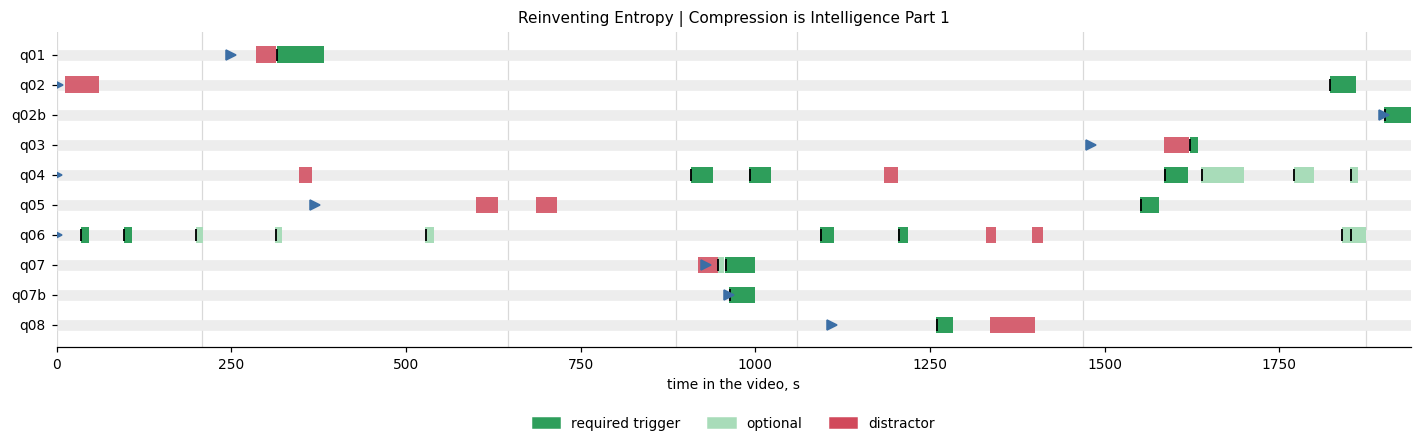

In [5]:
COL_REQ, COL_OPT, COL_DIS = "#2e9e5b", "#a8dcb9", "#d1495b"

def draw_chapters(ax, dur):
    for c in B["chapters"]:
        ax.axvline(c["start"], color="0.85", lw=0.8, zorder=0)
    ax.set_xlim(0, dur)

def global_map(samples=S, figsize=(13, 4.2)):
    dur = B["duration"]
    fig, ax = plt.subplots(figsize=figsize)
    draw_chapters(ax, dur)
    for i, s in enumerate(samples):
        y = len(samples) - 1 - i
        ax.hlines(y, 0, dur, color="0.93", lw=7, zorder=1)
        for d in s.get("distractor_windows", []):
            ax.barh(y, d["t_end"] - d["t_start"], left=d["t_start"], height=0.55,
                    color=COL_DIS, alpha=0.85, zorder=2)
        for t in s["triggers"]:
            ax.barh(y, max(t["t_end"] - t["t_start"], 4), left=t["t_start"], height=0.55,
                    color=COL_REQ if t["required"] else COL_OPT, zorder=3)
            ax.plot(t["t_ideal"], y, "|", color="black", ms=8, mew=1.2, zorder=4)
        ax.plot(s["question_time"], y, ">", color="#3b6ea5", ms=6, zorder=4)
    ax.set_yticks(range(len(samples)))
    ax.set_yticklabels([s["id"].split("__")[-1] for s in reversed(samples)])
    ax.set_xlabel("time in the video, s")
    ax.set_title(B["title"], fontsize=10)
    ax.legend(handles=[
        Patch(color=COL_REQ, label="required trigger"),
        Patch(color=COL_OPT, label="optional"),
        Patch(color=COL_DIS, label="distractor"),
    ], loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
    for sp in ("top", "right", "left"):
        ax.spines[sp].set_visible(False)
    plt.tight_layout()
    plt.show()
    plt.close(fig)

global_map()

## Coverage along the taxonomy axes

What matters here is not the prettiness but the holes: an empty cell of the cube
(act × relation × level) is what has not been annotated yet.

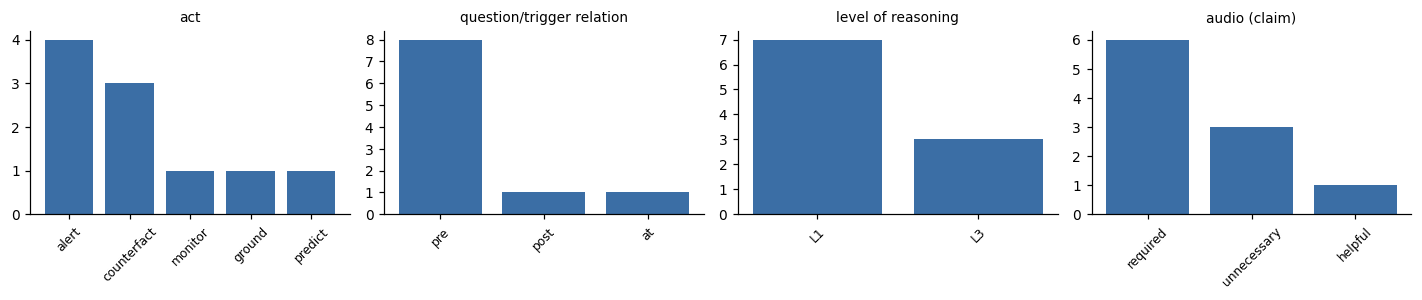

col_0                 L1  L3
act         relation        
alert       post       1   0
            pre        3   0
counterfact at         0   1
            pre        0   2
ground      pre        1   0
monitor     pre        1   0
predict     pre        1   0

In [6]:
def coverage(samples=S):
    fields = [("act", "act"), ("temporal_rel", "question/trigger relation"),
              ("reasoning_level", "level of reasoning"), ("audio_dependency_claim", "audio (claim)")]
    fig, axes = plt.subplots(1, len(fields), figsize=(13, 2.8))
    for ax, (f, title) in zip(axes, fields):
        vc = pd.Series([s.get(f) for s in samples]).value_counts()
        ax.bar(vc.index.astype(str), vc.values, color="#3b6ea5")
        ax.set_title(title, fontsize=9)
        ax.tick_params(axis="x", rotation=45, labelsize=8)
        ax.set_yticks(range(0, max(vc.values) + 1))
        for sp in ("top", "right"):
            ax.spines[sp].set_visible(False)
    plt.tight_layout(); plt.show(); plt.close(fig)

    cube = pd.crosstab(
        [ [s["act"] for s in samples], [s["temporal_rel"] for s in samples] ],
        [s["reasoning_level"] for s in samples])
    cube.index.names = ["act", "relation"]
    return cube

coverage()

## A detailed view of a question by index

`show(i)` — everything about one sample. `show(i, frames=False)` — without frames (faster),
`show(i, context=8)` — how many seconds of transcript to show around the window.

In [7]:
def timeline(s, figsize=(12, 1.5)):
    dur = s["video"]["duration"]
    fig, ax = plt.subplots(figsize=figsize)
    draw_chapters(ax, dur)
    ax.hlines(0, 0, dur, color="0.93", lw=16, zorder=1)
    for d in s.get("distractor_windows", []):
        ax.barh(0, d["t_end"] - d["t_start"], left=d["t_start"], height=0.6,
                color=COL_DIS, alpha=0.85, zorder=2)
    for t in s["triggers"]:
        ax.barh(0, max(t["t_end"] - t["t_start"], 4), left=t["t_start"], height=0.6,
                color=COL_REQ if t["required"] else COL_OPT, zorder=3)
        ax.plot(t["t_ideal"], 0, "|", color="black", ms=14, mew=1.4, zorder=4)
        ax.annotate(str(t["idx"]), (t["t_ideal"], 0.42), ha="center", fontsize=8)
    ax.plot(s["question_time"], 0, ">", color="#3b6ea5", ms=9, zorder=4)
    ax.set_ylim(-0.6, 0.7); ax.set_yticks([])
    ax.set_xlabel("time in the video, s")
    for sp in ("top", "right", "left"):
        ax.spines[sp].set_visible(False)
    plt.tight_layout(); plt.show(); plt.close(fig)


def show(i, frames=True, context=6.0, samples=None):
    s = (samples or S)[i]
    print("=" * 104)
    print(f"[{i}] {s['id']}")
    print(f"     {s['template']}  |  {s['act']} / {s['temporal_rel']} / {s['reasoning_level']}"
          f"  |  audio claim={s.get('audio_dependency_claim')}, measured={s['audio_dependency']}"
          f"  |  status={s['validation']['status']}")
    print("-" * 104)
    print("QUESTION (issued at", f"{s['question_time']:.0f} s):")
    print(wrap(s["question"], indent="  "))
    if s["validation"].get("notes"):
        print("\nANNOTATOR'S NOTE:")
        print(wrap(s["validation"]["notes"], indent="  "))

    timeline(s)

    for d in s.get("distractor_windows", []):
        print(f"\n  ✗ DISTRACTOR [{d['t_start']:.0f}, {d['t_end']:.0f})")
        print(wrap(d["why"], indent="      "))

    for t in s["triggers"]:
        mark = "●" if t["required"] else "○"
        print("\n" + "-" * 104)
        print(f"  {mark} TRIGGER {t['idx']}  [{t['t_start']:.1f}, {t['t_end']:.1f})  "
              f"t_ideal={t['t_ideal']:.1f}  modalities={'+'.join(t['trigger_modality'])}"
              + (f"  depends_on={t['depends_on']}" if t.get("depends_on") else "")
              + ("" if t["required"] else "  (optional)"))
        print(f"    chapter: {chapter_at(t['t_ideal'])}")
        print("\n    REFERENCE ANSWER:")
        print(wrap(t["response"], indent="      "))
        print("\n    RUBRIC:")
        for r in t["rubric"]:
            print(wrap(("— " + r), indent="      "))
        cues = transcript_at(t["t_start"], t["t_end"], pad=context)
        if cues:
            print("\n    TRANSCRIPT AROUND THE WINDOW:")
            for c in cues:
                inside = t["t_start"] <= c["start"] < t["t_end"]
                print(f"      {'>' if inside else ' '} {c['start']:7.1f}  {c['text']}")
        if frames:
            show_frames(t)

    print("\n    SOURCES (provenance.evidence):")
    for e in s["provenance"]["evidence"]:
        if e["type"] == "frame":
            head = f"frame {e['t']:.0f}"
        elif e["type"] == "speech":
            head = f"speech {e['t_start']:.1f}-{e['t_end']:.1f}"
        else:
            head = "other"
        print(wrap(f"— [{head}] {e['explanation']}", indent="      "))


def show_frames(t):
    ts = sorted({t["t_start"] + 0.5, t["t_ideal"], max(t["t_end"] - 0.5, t["t_ideal"])})
    fig, axes = plt.subplots(1, len(ts), figsize=(4.1 * len(ts), 2.6))
    axes = [axes] if len(ts) == 1 else list(axes)
    for ax, tt in zip(axes, ts):
        ax.imshow(plt.imread(frame_at(tt)))
        ax.set_title(f"t = {tt:.1f} s" + ("  ← t_ideal" if abs(tt - t["t_ideal"]) < 1e-6 else ""),
                     fontsize=8)
        ax.axis("off")
    plt.tight_layout(); plt.show(); plt.close(fig)

[0] 3b1b__l6DKRf-fAAM__q01
     counterfactual_on_appearance  |  counterfact / pre / L3  |  audio claim=unnecessary, measured=None  |  status=draft
--------------------------------------------------------------------------------------------------------
QUESTION (issued at 250 s):
  As soon as a table appears on screen FOR THE FIRST TIME in which each of the four instructions is
    matched with a code word, the code words being of different lengths, and their probabilities are
    visible at the same time, work it out yourself and say: what would the average number of bits
    per instruction become if the code words of the instructions “up” and “left” were swapped,
    leaving the probabilities as they are?

ANNOTATOR'S NOTE:
  the counterfactual is deliberately non-canonical: 2.5 is neither in the video nor in the
    textbooks. The window opens at 315, when the table is complete for the first time: only the code
    words and the probabilities are needed for the answer, there is no 

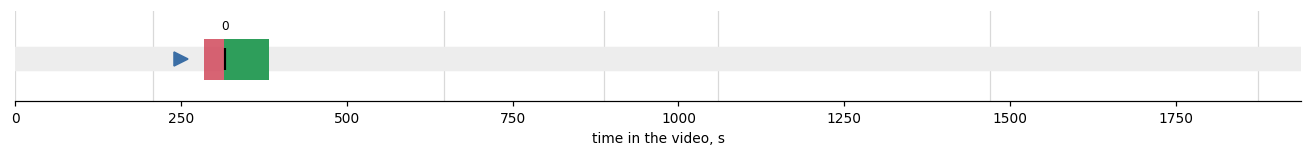


  ✗ DISTRACTOR [285, 314)
      the thought bubble shows the naive code 00/01/10/11 with arrows: the code words are all the
        same length, so swapping “up”<->“left” changes nothing and the question's condition (words
        of DIFFERENT lengths) is not met — even though the probabilities are already visible next to
        them

--------------------------------------------------------------------------------------------------------
  ● TRIGGER 0  [315.0, 382.0)  t_ideal=316.0  modalities=visual
    chapter: The warmup example

    REFERENCE ANSWER:
      2.5 bits per instruction. After the swap “up” (p=1/2) is encoded by the three bits 110 and
        “left” (p=1/8) by the single bit 0, so the average is 1/2·3 + 1/4·2 + 1/8·1 + 1/8·3 = 2.5.
        That is worse not only than the original 1.75 but also than the naive flat two-bit code.

    RUBRIC:
      — the number 2.5 is named (or 2.5 bits per instruction)
      — if a calculation is shown it must be a weighted one, with the

In [8]:
show(0, frames=False)

### Example: q02 — a trap for a premature answer

The correct number "1.0 bits/ch" hangs on the screen at second 40 with the caption "Limit?",
while the real answer is spoken only at 1822. Both early windows are annotated as distractors.

[1] 3b1b__l6DKRf-fAAM__q02
     premature_answer_trap  |  alert / pre / L1  |  audio claim=required, measured=None  |  status=rejected
--------------------------------------------------------------------------------------------------------
QUESTION (issued at 2 s):
  Wait for the moment when the author names Shannon's estimate for the compression limit of the
    English language, and say two things at once: the number itself and with how much preceding
    context that estimate was obtained. Until Shannon's estimate specifically is spoken — stay
    silent.

ANNOTATOR'S NOTE:
  a key sample for timing: the correct number is visible on screen 1785 s before the answer; level
    L1: both facts are spoken in a single line 1822-1829, and the difficulty of the sample lies
    entirely in the timing rather than in the reasoning | blind: before viewing, the semi-blind
    reviewer named both quantities of the rubric (≈1 bit per character, ≥100 letters of context)
    with no assumptions abou

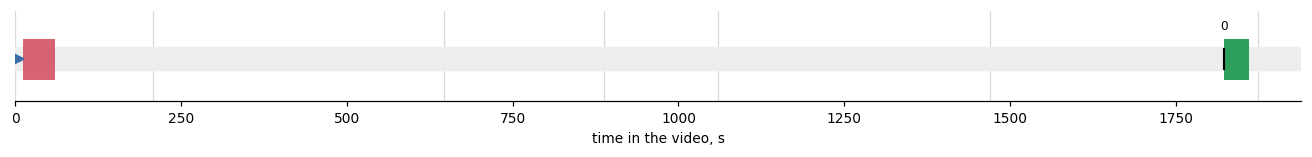


  ✗ DISTRACTOR [12, 34)
      the screen runs through the series ASCII 8.0 -> Huffman ~4.2 -> Neural methods ~1.1 bits per
        character; these are achievements of compression methods, not Shannon's estimate

  ✗ DISTRACTOR [34, 60)
      the screen shows a speedometer reading 1.0 bits/ch with the caption “Limit?” — the number
        coincides with the correct answer, but this is the statement of the question rather than the
        answer, and it comes without the conditions it was obtained under

--------------------------------------------------------------------------------------------------------
  ● TRIGGER 0  [1822.0, 1860.0)  t_ideal=1823.0  modalities=speech+visual
    chapter: Defining Entropy

    REFERENCE ANSWER:
      About one bit per character; the estimate was obtained when his interviewees had at least 100
        preceding letters of context.

    RUBRIC:
      — the value ≈1 bit per character is named
      — the condition is named: at least 100 preceding lett

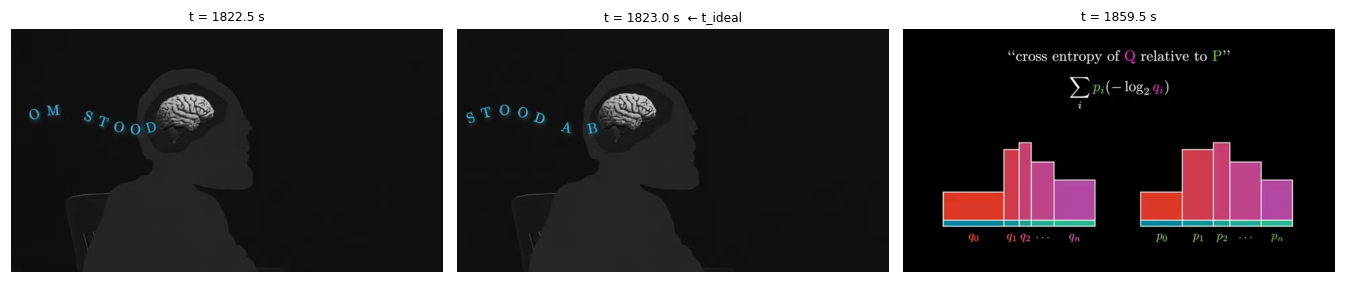


    SOURCES (provenance.evidence):
      — [speech 1822.0-1829.4] «at least 100 preceding letters of context ... about one bit per
        character»
      — [frame 1832] the counter “Bits Per Character ≈ 1.0”
      — [frame 15] ASCII 8.0 bits/ch
      — [frame 21] Huffman ~4.2
      — [frame 30] Neural ~1.1
      — [frame 40] the speedometer 1.0 bits/ch with the caption Limit?


In [9]:
show(idx_of("q02"))

### Example: q04 — multi-trigger monitoring

Five windows, the later ones with a `depends_on` on the earlier ones: the answer is obliged
to list everything accumulated by that moment.

[4] 3b1b__l6DKRf-fAAM__q04
     state_monitor  |  monitor / pre / L1  |  audio claim=helpful, measured=None  |  status=draft
--------------------------------------------------------------------------------------------------------
QUESTION (issued at 0 s):
  Keep track of which quantities the author defines formally — that is, writes out a formula for or
    gives a name to. Every time a new one is added, list all the quantities defined so far in order
    of appearance and say for the new one what it was obtained from.

ANNOTATOR'S NOTE:
  a multi-trigger sample; it tests the accumulation of state and depends_on | 2.5: the author speaks
    both the quantity itself and its derivation inside every window (907.6-918.6, 991.3,
    1582.5-1613.8) — this is unavoidable for a monitor over “formally defined quantities”: the act
    of defining is itself the trigger. The level was honestly lowered to an L1 alarm (checklist 2.5,
    cure 3). The discriminative power remained in listing the accu

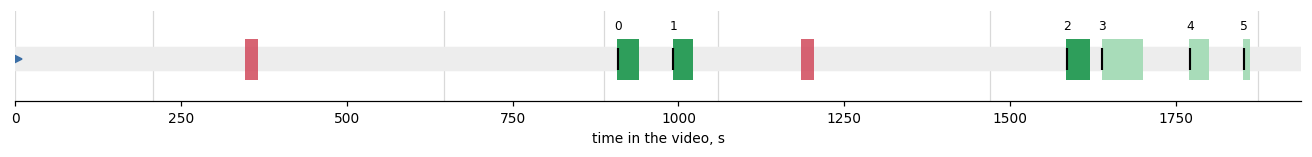


  ✗ DISTRACTOR [347, 366)
      the weighted sum for the robot's average number of bits is the arithmetic of a particular
        example, not the introduction of a formally defined quantity

  ✗ DISTRACTOR [1184, 1204)
      the chain rule and the property of logarithms are facts being used, not new definitions

--------------------------------------------------------------------------------------------------------
  ● TRIGGER 0  [907.6, 940.0)  t_ideal=908.6  modalities=visual+speech
    chapter: Defining information

    REFERENCE ANSWER:
      Defined: (1) the number of bits per message under perfect compression = -log2(p). Obtained by
        taking the logarithm of, and flipping the sign of, the relation p = 1/2^n, which follows
        from all 2^n messages being equally likely.

    RUBRIC:
      — the formula -log2(p) (or log2(1/p)) is named
      — it is stated that it was obtained from p = 2^(-n) by taking the logarithm
      — the list contains one quantity; mentioning the

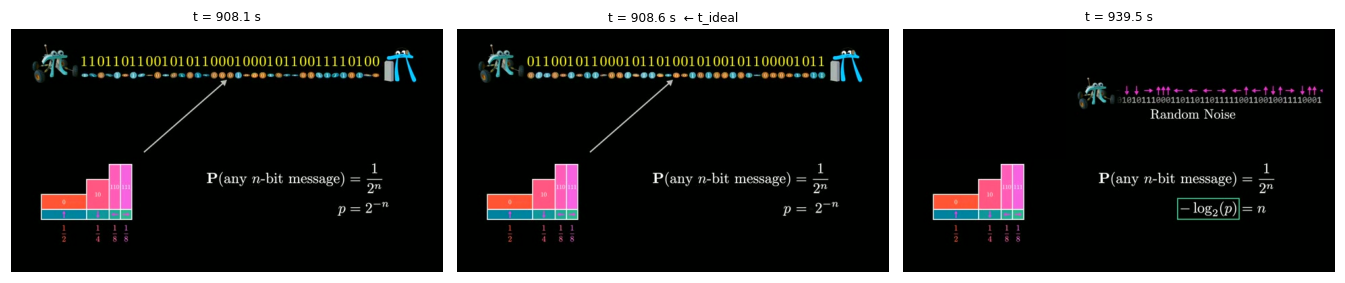


--------------------------------------------------------------------------------------------------------
  ● TRIGGER 1  [991.3, 1022.0)  t_ideal=992.3  modalities=speech  depends_on=[0]
    chapter: Defining information

    REFERENCE ANSWER:
      Defined: (1) the number of bits = -log2(p); (2) the information of an event — Shannon defines
        it by the same expression -log2(p), but now for any p rather than only for powers of two.

    RUBRIC:
      — the information of an event is named
      — it is stated that this is the same expression, generalised to non-integer values
      — both quantities are listed in the right order

    TRANSCRIPT AROUND THE WINDOW:
          987.4  which would mean that the output here is some fractional amount.
      >   991.3  In fact, he defined this expression to be the information of an event.
      >   996.2  The image I sometimes have in my head is to picture the probability of an event
      >  1000.5  with a little pie chart, and the infor

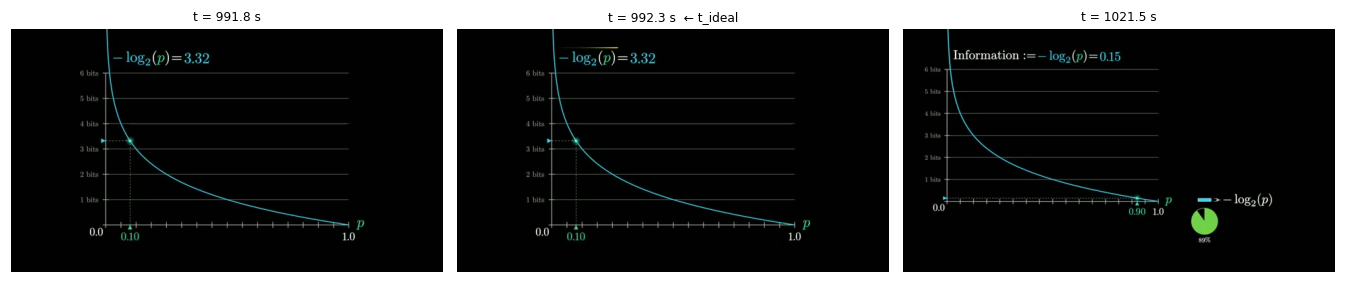


--------------------------------------------------------------------------------------------------------
  ● TRIGGER 2  [1585.0, 1620.0)  t_ideal=1586.0  modalities=visual+speech  depends_on=[0, 1]
    chapter: Defining Entropy

    REFERENCE ANSWER:
      Defined: (1) the number of bits = -log2(p); (2) the information of an event; (3) the average
        information per symbol = sum_i p_i·(-log2 p_i). Obtained by averaging the information of the
        individual symbols over their probabilities.

    RUBRIC:
      — the formula for the sum p·(-log p) is named
      — it is stated that this is a weighted average of the information over the distribution
      — all three quantities are listed in the right order

    TRANSCRIPT AROUND THE WINDOW:
         1577.7  messages are made out of, the average information per symbol should look like
         1582.5  adding up p times the negative log of p for each probability p in that distribution.
      >  1588.5  And take a moment to notice 

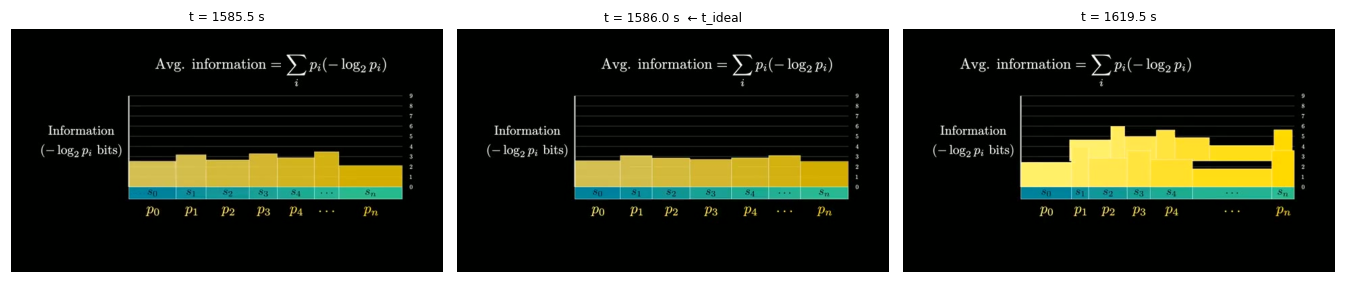


--------------------------------------------------------------------------------------------------------
  ○ TRIGGER 3  [1638.0, 1700.0)  t_ideal=1639.0  modalities=speech  depends_on=[2]  (optional)
    chapter: Defining Entropy

    REFERENCE ANSWER:
      There is no new formula, but the quantity from the previous item is given the name “entropy”
        and the symbol H.

    RUBRIC:
      — it is stated that this is the naming of an already introduced quantity rather than a new
        formula
      — the name “entropy” and the symbol H are named

    TRANSCRIPT AROUND THE WINDOW:
         1633.6  Nevertheless, it's important enough to deserve a name.
         1636.7  And there's a fun story about how John von Neumann supposedly told Shannon that he should
      >  1641.5  call this expression entropy, since, for one thing,
      >  1644.3  it resembles an expression already used for the idea of entropy in statistical
      >  1648.6  mechanics, and for another, quote, nobody kno

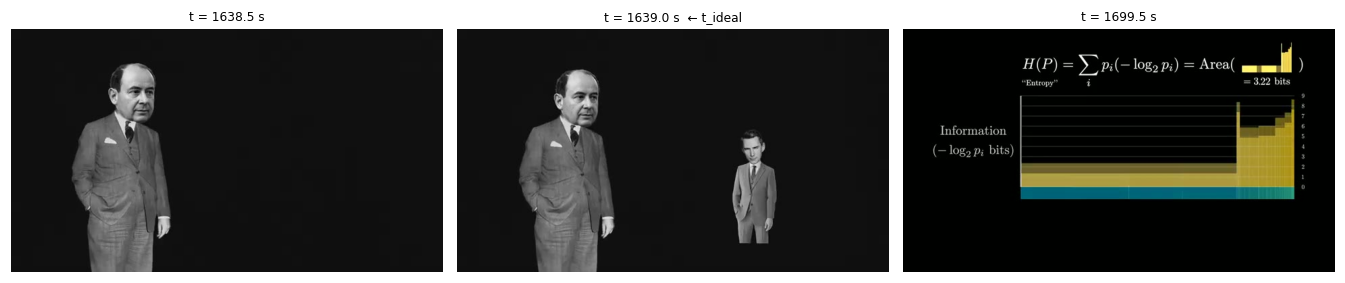


--------------------------------------------------------------------------------------------------------
  ○ TRIGGER 4  [1770.5, 1800.0)  t_ideal=1771.5  modalities=speech  depends_on=[2]  (optional)
    chapter: Defining Entropy

    REFERENCE ANSWER:
      The entropy rate of a stochastic process is mentioned — the generalisation to the case where
        the distribution of symbols changes; no formula is written out.

    RUBRIC:
      — the entropy rate is named
      — it is noted that no formula is given

    TRANSCRIPT AROUND THE WINDOW:
         1764.7  In particular, he spent a ton of time contemplating
         1767.6  the compressibility of natural language.
      >  1770.5  This requires a more general notion of entropy,
      >  1772.8  something known as the entropy rate for a stochastic process.
      >  1776.4  But it's the same basic question.
      >  1778.2  What is the average information per symbol, except in
      >  1781.2  this case we're now averaging over all

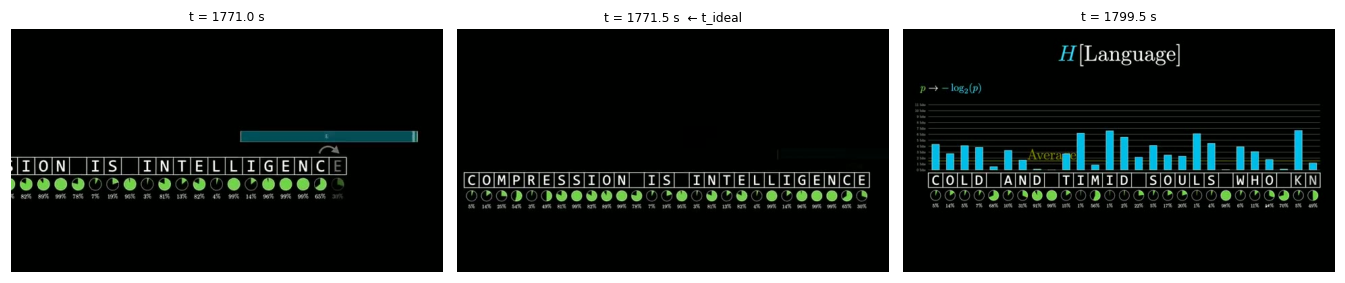


--------------------------------------------------------------------------------------------------------
  ○ TRIGGER 5  [1851.1, 1862.0)  t_ideal=1852.1  modalities=speech  depends_on=[2]  (optional)
    chapter: Defining Entropy

    REFERENCE ANSWER:
      Cross-entropy is mentioned as a variation of entropy — the name is given, no formula is
        written out; the discussion is postponed to part two.

    RUBRIC:
      — cross-entropy is named
      — it is noted that there is no formula, only the name

    TRANSCRIPT AROUND THE WINDOW:
         1846.5  encoding and decoding, you can get surprisingly close to this limit in practice.
      >  1851.1  Before then, it helps to understand a variation on entropy, known as cross-entropy,
      >  1855.9  asking both how and why it's used in training large language models.
      >  1860.4  If you want to learn that, as well as a few fun related ideas like how
         1864.2  large models are distilled into smaller ones,


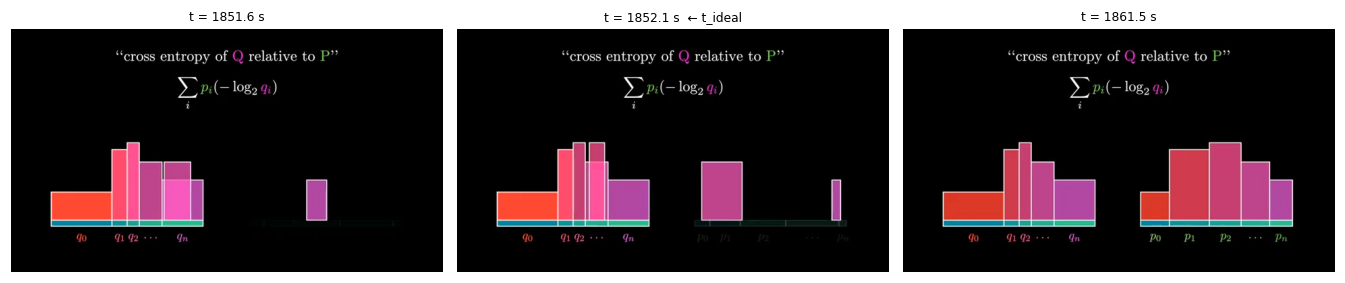


    SOURCES (provenance.evidence):
      — [frame 920] on screen P(any n-bit message)=1/2^n and -log2(p)=n
      — [speech 907.6-920.9] «If you take the log base 2 of both sides here and then negate,»
      — [speech 991.3-995.4] «In fact, he defined this expression to be the information of an
        event.»
      — [speech 1573.1-1587.7] «For any given probability distribution, characterizing whatever
        symbols your»
      — [speech 1660.6-1666.7] «Now, whatever the true story is, Shannon did call this quantity
        entropy,»
      — [speech 1770.5-1778.0] «This requires a more general notion of entropy,»
      — [speech 1636.7-1648.6] the quantity is offered the name “entropy”
      — [speech 1851.1-1855.9] «a variation on entropy, known as cross-entropy»


In [10]:
show(idx_of("q04"), context=3)

## Leaf through them all

Below are all the questions in a row, without frames (otherwise the saved notebook bloats). For an interactive view with frames there is `browse()`: it gives a slider over the questions, but it is marked `skip-execution`, because the widget blocks the kernel during a batch run.

Without `ipywidgets`, simply call `show(i)` by hand.

[0] 3b1b__l6DKRf-fAAM__q01
     counterfactual_on_appearance  |  counterfact / pre / L3  |  audio claim=unnecessary, measured=None  |  status=draft
--------------------------------------------------------------------------------------------------------
QUESTION (issued at 250 s):
  As soon as a table appears on screen FOR THE FIRST TIME in which each of the four instructions is
    matched with a code word, the code words being of different lengths, and their probabilities are
    visible at the same time, work it out yourself and say: what would the average number of bits
    per instruction become if the code words of the instructions “up” and “left” were swapped,
    leaving the probabilities as they are?

ANNOTATOR'S NOTE:
  the counterfactual is deliberately non-canonical: 2.5 is neither in the video nor in the
    textbooks. The window opens at 315, when the table is complete for the first time: only the code
    words and the probabilities are needed for the answer, there is no 

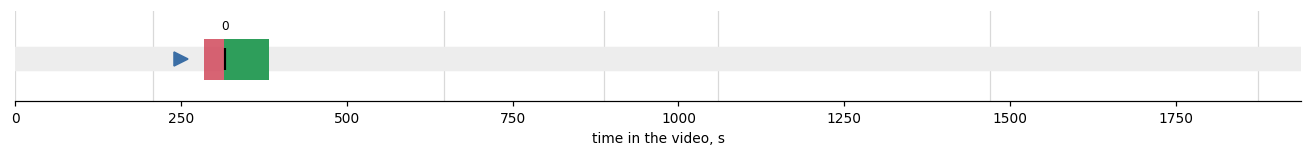


  ✗ DISTRACTOR [285, 314)
      the thought bubble shows the naive code 00/01/10/11 with arrows: the code words are all the
        same length, so swapping “up”<->“left” changes nothing and the question's condition (words
        of DIFFERENT lengths) is not met — even though the probabilities are already visible next to
        them

--------------------------------------------------------------------------------------------------------
  ● TRIGGER 0  [315.0, 382.0)  t_ideal=316.0  modalities=visual
    chapter: The warmup example

    REFERENCE ANSWER:
      2.5 bits per instruction. After the swap “up” (p=1/2) is encoded by the three bits 110 and
        “left” (p=1/8) by the single bit 0, so the average is 1/2·3 + 1/4·2 + 1/8·1 + 1/8·3 = 2.5.
        That is worse not only than the original 1.75 but also than the naive flat two-bit code.

    RUBRIC:
      — the number 2.5 is named (or 2.5 bits per instruction)
      — if a calculation is shown it must be a weighted one, with the

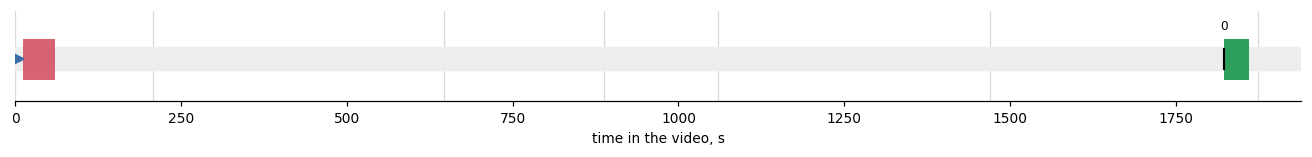


  ✗ DISTRACTOR [12, 34)
      the screen runs through the series ASCII 8.0 -> Huffman ~4.2 -> Neural methods ~1.1 bits per
        character; these are achievements of compression methods, not Shannon's estimate

  ✗ DISTRACTOR [34, 60)
      the screen shows a speedometer reading 1.0 bits/ch with the caption “Limit?” — the number
        coincides with the correct answer, but this is the statement of the question rather than the
        answer, and it comes without the conditions it was obtained under

--------------------------------------------------------------------------------------------------------
  ● TRIGGER 0  [1822.0, 1860.0)  t_ideal=1823.0  modalities=speech+visual
    chapter: Defining Entropy

    REFERENCE ANSWER:
      About one bit per character; the estimate was obtained when his interviewees had at least 100
        preceding letters of context.

    RUBRIC:
      — the value ≈1 bit per character is named
      — the condition is named: at least 100 preceding lett

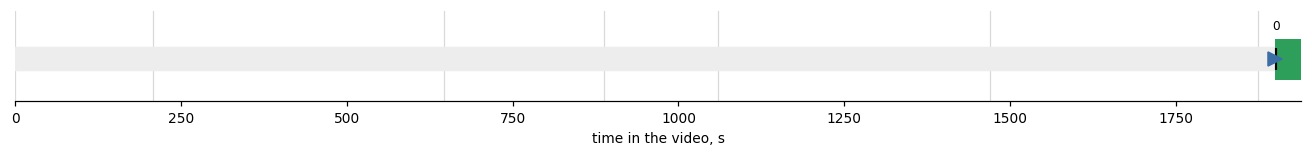


--------------------------------------------------------------------------------------------------------
  ● TRIGGER 0  [1900.0, 1939.0)  t_ideal=1901.0  modalities=speech+visual
    chapter: 3b1b Talent

    REFERENCE ANSWER:
      About one bit per character; the estimate was obtained when his interviewees had at least 100
        preceding letters of context.

    RUBRIC:
      — the value ≈1 bit per character is named
      — the condition is named: at least 100 preceding letters of context
      — it is stated that this is an estimate from experiments with people rather than a measurement
        by an algorithm
      — an answer with the number alone, without the condition about 100 letters, is partial (1 of
        2)
      — do NOT count 1.1 bits per character — that is the result of neural methods, from second 30
      — do NOT count 4.2 bits per character — that is Huffman, from second 21

    TRANSCRIPT AROUND THE WINDOW:
         1895.9  it's almost impossible to get a tru

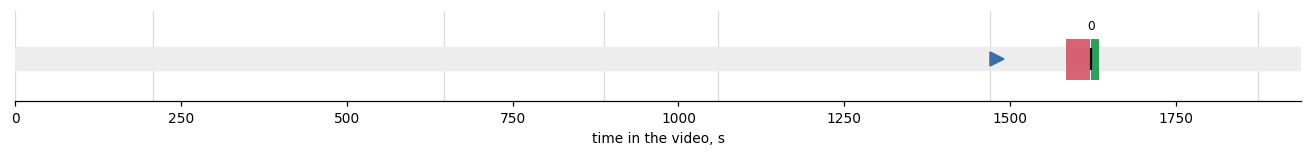


  ✗ DISTRACTOR [1585, 1621)
      the formula is already on screen and reasoning about its applicability is possible here — but
        the author has not named the condition yet, and the question asks specifically about the
        moment at which he does

--------------------------------------------------------------------------------------------------------
  ● TRIGGER 0  [1621.8, 1633.6)  t_ideal=1622.8  modalities=speech
    chapter: Defining Entropy

    REFERENCE ANSWER:
      The formula holds only when every new symbol follows one and the same distribution; the author
        immediately adds that this is true in the robot example but not in English.

    RUBRIC:
      — the condition is named: all symbols follow one and the same distribution (i.i.d., no
        dependence on context)
      — count a restatement in the reviewer's own words: “the formula does not account for a symbol
        depending on the preceding context”
      — do NOT count a general “the formula is app

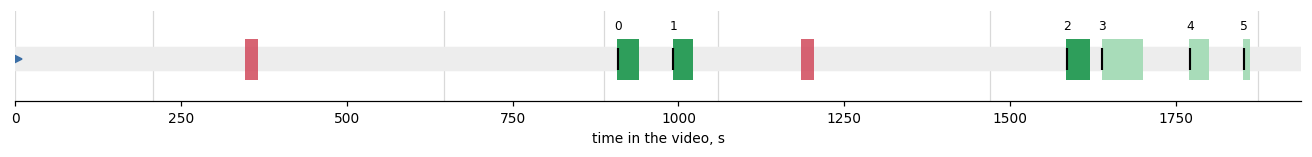


  ✗ DISTRACTOR [347, 366)
      the weighted sum for the robot's average number of bits is the arithmetic of a particular
        example, not the introduction of a formally defined quantity

  ✗ DISTRACTOR [1184, 1204)
      the chain rule and the property of logarithms are facts being used, not new definitions

--------------------------------------------------------------------------------------------------------
  ● TRIGGER 0  [907.6, 940.0)  t_ideal=908.6  modalities=visual+speech
    chapter: Defining information

    REFERENCE ANSWER:
      Defined: (1) the number of bits per message under perfect compression = -log2(p). Obtained by
        taking the logarithm of, and flipping the sign of, the relation p = 1/2^n, which follows
        from all 2^n messages being equally likely.

    RUBRIC:
      — the formula -log2(p) (or log2(1/p)) is named
      — it is stated that it was obtained from p = 2^(-n) by taking the logarithm
      — the list contains one quantity; mentioning the

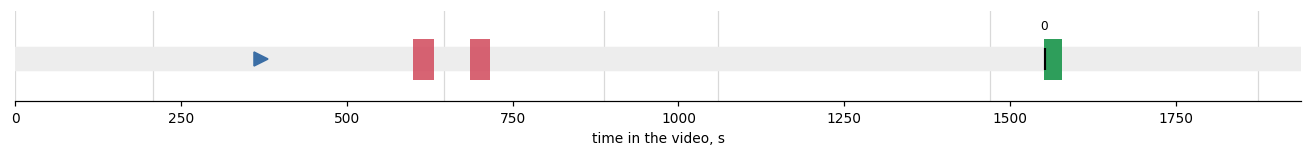


  ✗ DISTRACTOR [600, 631)
      the author points out the coincidence of the fractions and the probabilities in the robot
        example and calls it the founding insight, but he uses no computed number in doing so

  ✗ DISTRACTOR [686, 716)
      what is applied here is the second student's code itself, not the quantity computed in the
        example; the moment looks like a fit, but what was asked about is the numeric result

--------------------------------------------------------------------------------------------------------
  ● TRIGGER 0  [1551.0, 1578.0)  t_ideal=1552.0  modalities=speech
    chapter: Defining Entropy

    REFERENCE ANSWER:
      The author says that the quantity he is now introducing is one we have already computed — that
        same weighted sum of 1.75 bits per instruction from the robot example. Since that code was
        perfect, the length of each symbol's code word equalled its information, and therefore the
        weighted sum was the average info

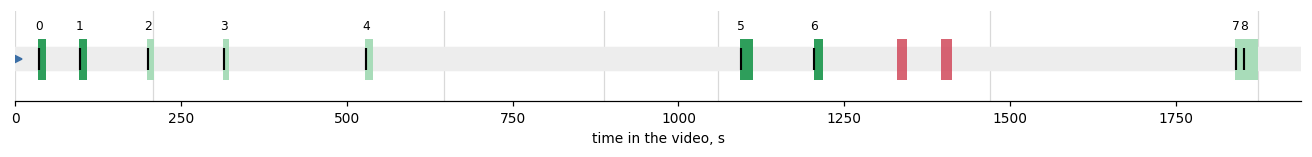


  ✗ DISTRACTOR [1330, 1345)
      “So instead of using raw statistics, a little bit later, Shannon analyzed…” — “later” refers
        to the chronology of Shannon's work, not to the video; nothing is being postponed

  ✗ DISTRACTOR [1396, 1412)
      “A bit later still, in his 1950 paper…” — historical time again, not a postponement

--------------------------------------------------------------------------------------------------------
  ● TRIGGER 0  [34.2, 46.0)  t_ideal=35.2  modalities=speech
    chapter: On “Compression is intelligence.”

    REFERENCE ANSWER:
      What is postponed is the numeric estimate of the compression limit: the author promises to
        name it at the end.

    RUBRIC:
      — it is stated that what is postponed is a specific number / the estimate of the limit
      — it is stated that the author will come back to it at the end

    TRANSCRIPT AROUND THE WINDOW:
           32.1  But again, what's the limit?
      >    34.2  I'm guessing many of you mig

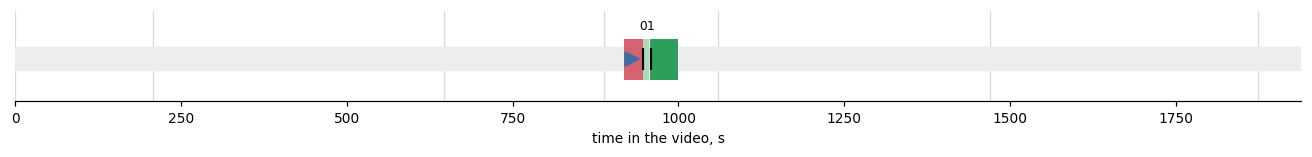


  ✗ DISTRACTOR [918, 946)
      the formula -log2(p) = n is already circled on screen, but the specific values of p and their
        heights have not been shown yet (at 941 only two of the four squares are there) — there is
        nowhere to read the positions of the bars from, and an answer here could only be general
        reasoning about ln2

--------------------------------------------------------------------------------------------------------
  ○ TRIGGER 0  [946.0, 955.4)  t_ideal=947.0  modalities=visual  (optional)
    chapter: Defining information

    REFERENCE ANSWER:
      The same four pairs have already been shown, not as a graph but as separate square diagrams:
        -log2(1/2)=1, -log2(1/4)=2, -log2(1/8)=3, -log2(1/16)=4. With the natural logarithm the
        values become ln2, 2ln2, 3ln2, 4ln2, that is, approximately 0.69, 1.39, 2.08 and 2.77.

    RUBRIC:
      — all four pairs of p and the corresponding values are named
      — the new values or the common fac

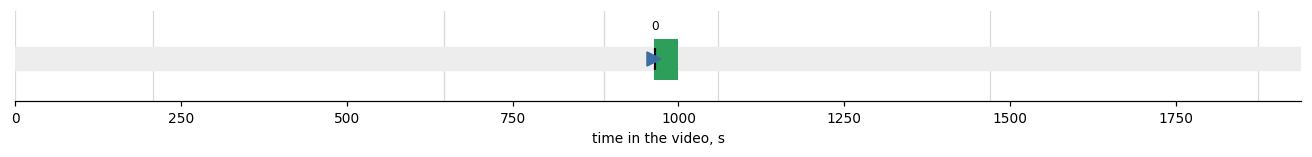


--------------------------------------------------------------------------------------------------------
  ● TRIGGER 0  [963.0, 1000.0)  t_ideal=964.0  modalities=visual
    chapter: Defining information

    REFERENCE ANSWER:
      The bars are drawn for p = 1/16, 1/8, 1/4 and 1/2, and their heights are 4, 3, 2 and 1 bits.
        Switching to the natural logarithm multiplies every height by ln2 ≈ 0.693, giving
        approximately 2.77, 2.08, 1.39 and 0.69; the units change from bits to nats.

    RUBRIC:
      — all four positions of the bars are named: p = 1/16, 1/8, 1/4, 1/2
      — the original heights 4, 3, 2, 1 bits are named
      — the common factor ln2 ≈ 0.693 (or division by log2(e)) is stated — this counts as an
        alternative to the next item rather than in addition to it
      — the new values ≈2.77, 2.08, 1.39, 0.69 are named for at least two of the bars
      — mentioning the change of units from bits to nats improves the score but is not required
      — do NOT

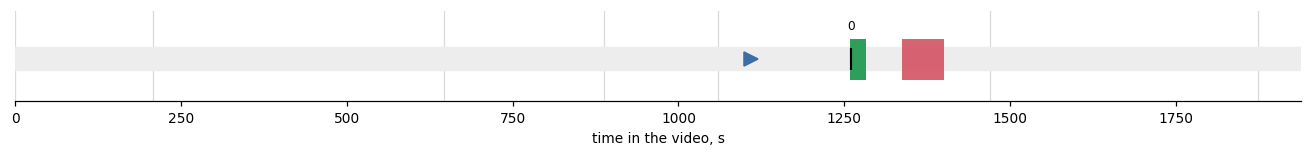


  ✗ DISTRACTOR [1337, 1400)
      here the author names Betty and describes the guessing game itself — the source is named, and
        an answer confined to this window looks complete, but the second half (how a person differs
        from a table of frequencies) is not here: the author speaks it only at 1437-1458. An answer
        from here is incomplete under the rubric

--------------------------------------------------------------------------------------------------------
  ● TRIGGER 0  [1259.0, 1283.0)  t_ideal=1260.0  modalities=speech
    chapter: Information of language

    REFERENCE ANSWER:
      The source is people, native speakers: Shannon asked a person to guess each next letter and
        reconstructed the probabilities from those guesses. That source has no sparsity problem
        because a person is not a table of frequencies but a model of the language: they give an
        estimate for a context they have never seen verbatim, generalising rather than looking for

In [11]:
for i in range(len(S)):
    show(i, frames=False, context=2)

In [12]:
def browse(samples=None):
    # a slider over the questions; do not call under nbconvert — it blocks the kernel
    from ipywidgets import interact, IntSlider, Checkbox
    data = samples or S
    return interact(
        lambda i, frames, context: show(i, frames=frames, context=context, samples=data),
        i=IntSlider(min=0, max=len(data) - 1, step=1, value=0, description="question"),
        frames=Checkbox(value=True, description="frames"),
        context=IntSlider(min=0, max=20, step=1, value=6, description="context, s"),
    )

In [ ]:
browse()

## What else is in the bundle

Besides the annotation, the materials it was made from are at hand.

In [13]:
# the formulas pulled out of the manim source: useful when annotating "what is on the screen"
pd.DataFrame(B["formulas"]).head(15)

,file,line,scene,call,text
0,_2026/cross_entropy/arithmetic_coding.py,390,ProbababilityOfAWord,Tex,P(``math\
1,_2026/cross_entropy/entropy.py,99,CompressibilitOfText,Tex,\vdots
2,_2026/cross_entropy/entropy.py,133,CompressibilitOfText,Tex,\rightarrow
3,_2026/cross_entropy/entropy.py,137,CompressibilitOfText,Tex,\sim 8.0 \text{bits} / \text{ch}
4,_2026/cross_entropy/entropy.py,146,CompressibilitOfText,Text,ASCII
5,_2026/cross_entropy/entropy.py,147,CompressibilitOfText,Text,Huffman
6,_2026/cross_entropy/entropy.py,148,CompressibilitOfText,Text,Neural methods
7,_2026/cross_entropy/entropy.py,251,SpaceOfCodewords,Tex,\vdots
8,_2026/cross_entropy/entropy.py,292,SpaceOfCodewords,TexText,{n + 1} bit{
9,_2026/cross_entropy/entropy.py,515,IntroduceRandomNoise,Text,Random Noise


In [14]:
# the chapters and their durations
ch = pd.DataFrame(B["chapters"])
ch["dur., s"] = (ch["end"] - ch["start"]).round(1)
ch

,start,end,title,"dur., s"
0,0,208,On “Compression is intelligence.”,208
1,208,646,The warmup example,438
2,646,887,What perfect compression looks like,241
3,887,1060,Defining information,173
4,1060,1469,Information of language,409
5,1469,1874,Defining Entropy,405
6,1874,1939,3b1b Talent,65
